<a href="https://colab.research.google.com/github/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/blob/main/advanced_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Silhouette scores:
  KMeans      : 0.389
  Hierarchical: 0.372
  DBSCAN      : 0.541

DBSCAN clusters found: 3
DBSCAN noise points  : 8


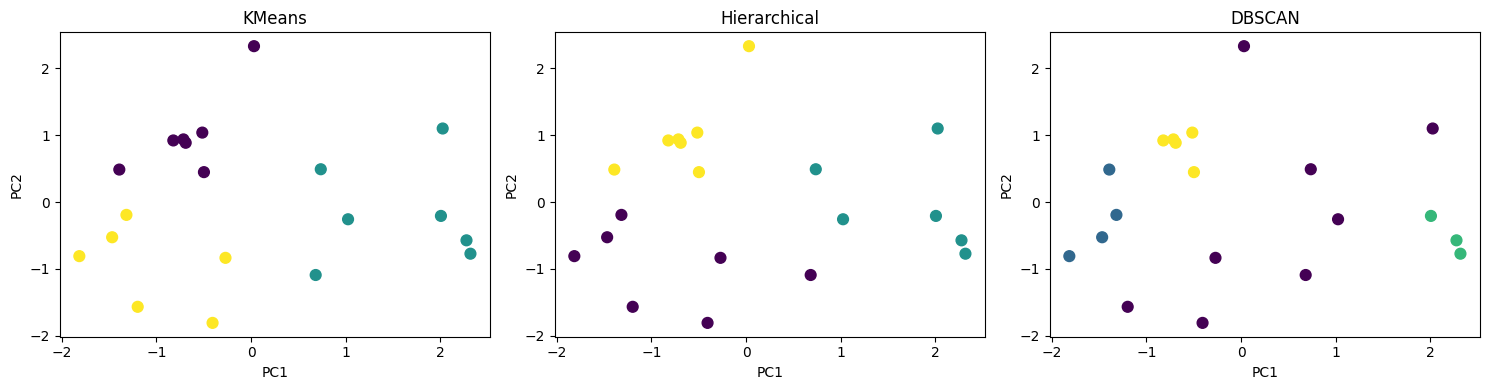

PASS: test_hierarchical_labels
PASS: test_dbscan_length
PASS: test_bad_hierarchical_k
PASS: test_bad_dbscan_eps


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

URL = "https://raw.githubusercontent.com/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/main/Mall_Customers.csv"
FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

df = pd.read_csv(URL).drop_duplicates().dropna(subset=FEATURES)
X = StandardScaler().fit_transform(df[FEATURES])
X_2d = PCA(n_components=2, random_state=42).fit_transform(X)


def hierarchical(X, n_clusters=3, linkage="ward"):
    """Hierarchical (agglomerative) clustering."""
    if n_clusters < 2 or n_clusters > len(X):
        raise ValueError("n_clusters must be between 2 and number of rows")
    return AgglomerativeClustering(n_clusters=n_clusters, linkage=linkage).fit_predict(X)


def dbscan(X, eps=0.9, min_samples=3):
    """DBSCAN clustering. Label -1 means noise (outlier)."""
    if eps <= 0 or min_samples < 1:
        raise ValueError("eps must be > 0 and min_samples >= 1")
    return DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)


def safe_silhouette(X, labels):
    """Silhouette score ignoring noise points; None if not possible."""
    mask = labels != -1
    if len(set(labels[mask])) < 2:
        return None
    return round(silhouette_score(X[mask], labels[mask]), 3)


km_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
hc_labels = hierarchical(X, 3)
db_labels = dbscan(X)

df["KMeans"] = km_labels
df["Hierarchical"] = hc_labels
df["DBSCAN"] = db_labels

print("Silhouette scores:")
print("  KMeans      :", safe_silhouette(X, km_labels))
print("  Hierarchical:", safe_silhouette(X, hc_labels))
print("  DBSCAN      :", safe_silhouette(X, db_labels))
print("\nDBSCAN clusters found:", len(set(db_labels) - {-1}))
print("DBSCAN noise points  :", int((db_labels == -1).sum()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, lab) in zip(axes, [("KMeans", km_labels),
                                  ("Hierarchical", hc_labels),
                                  ("DBSCAN", db_labels)]):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=lab, cmap="viridis", s=60)
    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()


def test_hierarchical_labels():
    assert len(set(hc_labels)) == 3

def test_dbscan_length():
    assert len(db_labels) == len(X)

def test_bad_hierarchical_k():
    try:
        hierarchical(X, 1)
        assert False
    except ValueError:
        pass

def test_bad_dbscan_eps():
    try:
        dbscan(X, eps=0)
        assert False
    except ValueError:
        pass

for t in [test_hierarchical_labels, test_dbscan_length,
          test_bad_hierarchical_k, test_bad_dbscan_eps]:
    t()
    print("PASS:", t.__name__)